<a href="https://colab.research.google.com/github/AndresMontesDeOca/vision_computadora_II/blob/VpC2_2026/CS_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# !pip install roboflow ultralytics

import os
import yaml
import json
import random
import cv2
import matplotlib.pyplot as plt
from google.colab import userdata
from google.colab import drive
from roboflow import Roboflow

# Montar Google Drive al inicio de la sesión
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:


# Ruta esperada del dataset
dataset_path = '/content/Counter-Strike-1'

# Verificar si el dataset ya existe en el entorno
if not os.path.exists(dataset_path):
    print("El dataset no fue detectado. Iniciando descarga desde Roboflow...")
    # Obtener la clave API de Roboflow de los secretos de Colab de manera segura
    api_key = userdata.get("ROBOFLOW_API_KEY")
    rf = Roboflow(api_key=api_key)

    # Descarga del dataset en formato YOLOv11
    project = rf.workspace("counter-strike-uovxc").project("counter-strike-h9y80")
    version = project.version(1)
    dataset = version.download("yolov11")
else:
    print(f"El dataset ya existe en '{dataset_path}'. Se omitió la descarga para optimizar tiempo.")

El dataset no fue detectado. Iniciando descarga desde Roboflow...
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Counter-Strike-1 in yolov11:: 100%|██████████| 7374/7374 [00:00<00:00, 8220.47it/s]


In [4]:
import os
import glob
import yaml
import json

# Cargar y mostrar la configuración de clases y rutas
data_yaml_path = '/content/Counter-Strike-1/data.yaml'
with open(data_yaml_path, 'r') as file:
    dataset_info = yaml.safe_load(file)

print("Estructura y clases del dataset:")
print(json.dumps(dataset_info, indent=4))
print("\n" + "="*40 + "\n")

# Contar imágenes en cada carpeta del dataset
# Roboflow descarga todo dentro de '/content/Counter-Strike-1'
# Si la ruta es '../train/images', queremos buscar dentro de '/content/Counter-Strike-1/train/images'
dataset_root = '/content/Counter-Strike-1'

for split in ['train', 'val', 'test']:
    yaml_key = split
    if split == 'val' and 'val' not in dataset_info and 'valid' in dataset_info:
        yaml_key = 'valid'

    if yaml_key in dataset_info:
        # Limpiamos la ruta relativa eliminando '../' inicial para buscar directamente dentro del directorio descargado
        split_path = dataset_info[yaml_key].lstrip('./').replace('../', '')
        full_split_path = os.path.abspath(os.path.join(dataset_root, split_path))

        # Buscar extensiones de imágenes
        image_extensions = ('*.jpg', '*.jpeg', '*.png', '*.bmp', '*.JPG', '*.JPEG', '*.PNG')
        images_found = []
        for ext in image_extensions:
            images_found.extend(glob.glob(os.path.join(full_split_path, ext)))

        print(f"Carpeta '{split}': {len(images_found)} imágenes encontradas en {full_split_path}")
    else:
        print(f"No se encontró la definición de '{split}' o '{yaml_key}' en data.yaml")

Estructura y clases del dataset:
{
    "train": "../train/images",
    "val": "../valid/images",
    "test": "../test/images",
    "nc": 2,
    "names": [
        "ct",
        "t"
    ],
    "roboflow": {
        "workspace": "counter-strike-uovxc",
        "project": "counter-strike-h9y80",
        "version": 1,
        "license": "CC BY 4.0",
        "url": "https://universe.roboflow.com/counter-strike-uovxc/counter-strike-h9y80/dataset/1"
    }
}


Carpeta 'train': 2577 imágenes encontradas en /content/Counter-Strike-1/train/images
Carpeta 'val': 736 imágenes encontradas en /content/Counter-Strike-1/valid/images
Carpeta 'test': 368 imágenes encontradas en /content/Counter-Strike-1/test/images


In [6]:
############################################################################
def plot_yolo_sample(img_path, lbl_path, class_names):
    """Dibuja cajas YOLO en una imagen usando azul para CT y rojo para Terroristas."""
    if not os.path.exists(img_path):
        print(f"No se encontró la imagen: {img_path}")
        return

    # Cargar y convertir imagen
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w, _ = image.shape

    # Colores en RGB: Azul para clase 0 (ct), Rojo para clase 1 (t)
    colors = [(0, 0, 255), (255, 0, 0)]

    if os.path.exists(lbl_path):
        with open(lbl_path, 'r') as f:
            lines = f.readlines()

        for line in lines:
            parts = line.strip().split()
            if len(parts) == 5:
                cls_id = int(parts[0])
                x_center, y_center, bbox_w, bbox_h = map(float, parts[1:])

                # Convertir coordenadas YOLO normalizadas a píxeles
                x1 = int((x_center - bbox_w / 2) * w)
                y1 = int((y_center - bbox_h / 2) * h)
                x2 = int((x_center + bbox_w / 2) * w)
                y2 = int((y_center + bbox_h / 2) * h)

                # Dibujar rectángulo y texto informativo
                color = colors[cls_id % len(colors)]
                cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)

                label = class_names[cls_id] if cls_id < len(class_names) else str(cls_id)
                cv2.putText(image, label, (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

    plt.figure(figsize=(10, 10))
    plt.imshow(image)
    plt.axis('off')
    plt.show()

############################################################################
def plot_random_samples(images_dir, labels_dir, class_names, num_samples=3):
    """Selecciona de manera aleatoria 'num_samples' imágenes y las renderiza con sus etiquetas."""
    if not os.path.exists(images_dir) or not os.path.exists(labels_dir):
        print("No se encontraron las carpetas de imágenes o etiquetas.")
        return

    all_images = [f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    if len(all_images) < num_samples:
        print(f"No hay suficientes imágenes disponibles (Encontradas: {len(all_images)}).")
        return

    selected_images = random.sample(all_images, num_samples)

    for img_name in selected_images:
        lbl_name = img_name.rsplit('.', 1)[0] + '.txt'
        img_path = os.path.join(images_dir, img_name)
        lbl_path = os.path.join(labels_dir, lbl_name)

        print(f"Mostrando muestra aleatoria: {img_name}")
        plot_yolo_sample(img_path, lbl_path, class_names)

Mostrando muestra aleatoria: csdata_157-6-_png.rf.27d50ead2eb6d98f86bf9edee14acd57.jpg


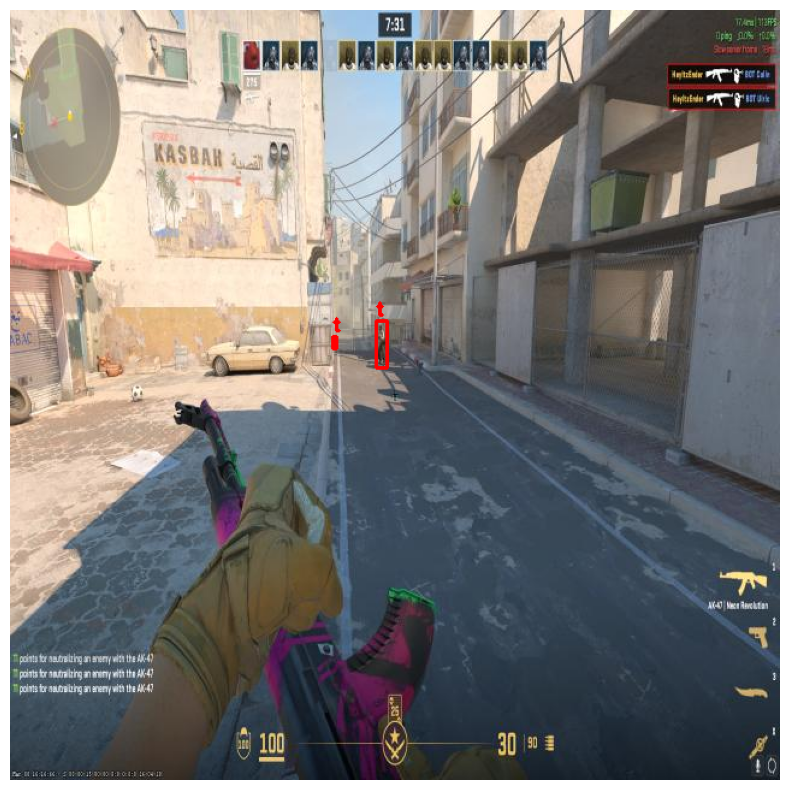

Mostrando muestra aleatoria: csdata_127_png.rf.842ac833cde8ccf5c118aac375e52653.jpg


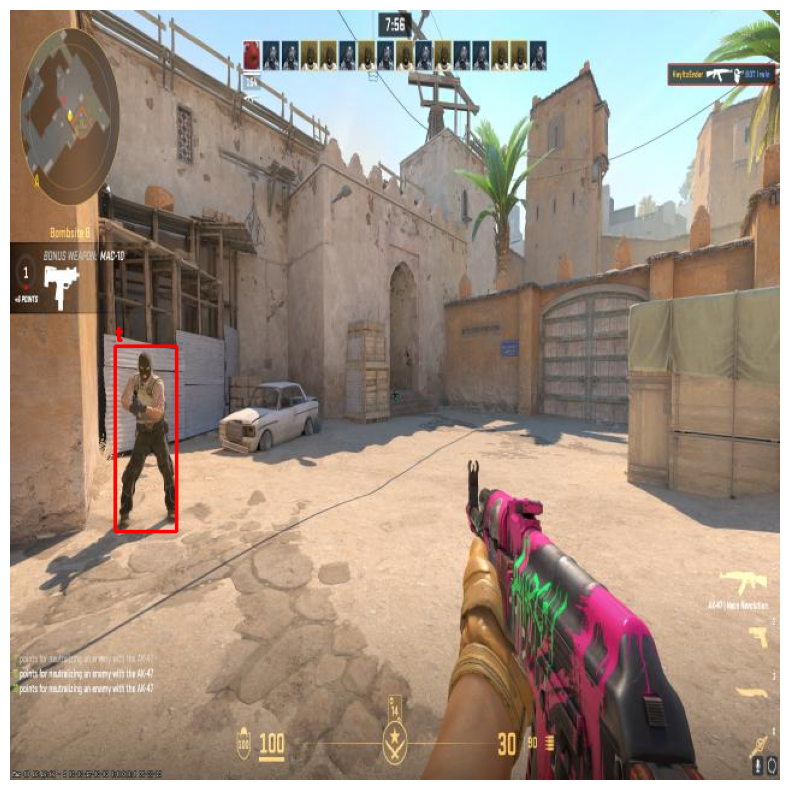

Mostrando muestra aleatoria: csdata_421-3-_png.rf.449f5e2c5a5e25b90edb981c3a0c3156.jpg


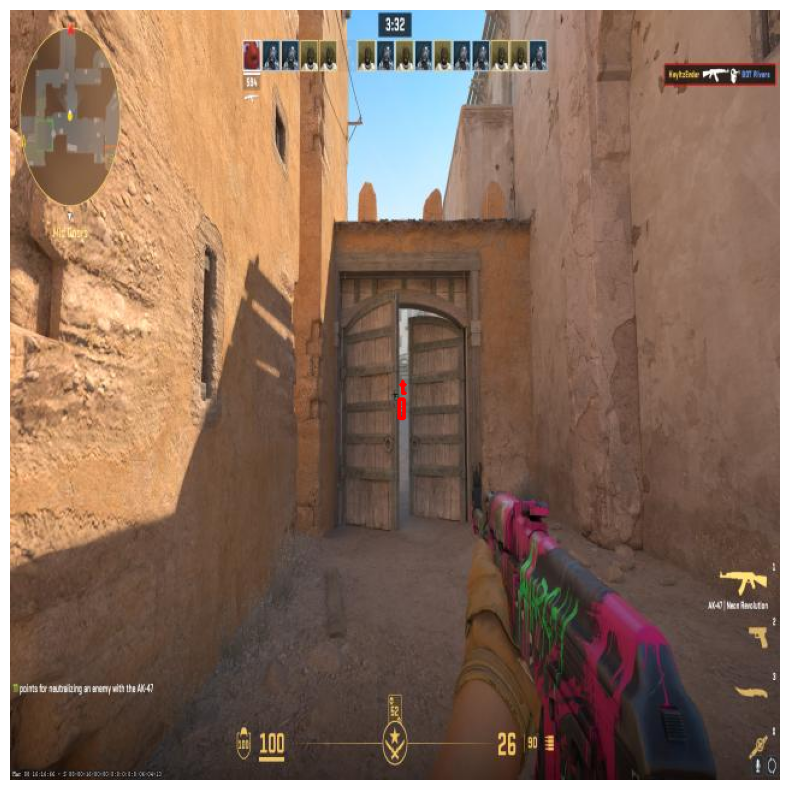

In [7]:
# Definición de rutas principales
images_dir = '/content/Counter-Strike-1/train/images'
labels_dir = '/content/Counter-Strike-1/train/labels'
class_names = dataset_info.get('names', ['ct', 't'])

# Ejecutar visualización de 3 imágenes al azar
plot_random_samples(images_dir, labels_dir, class_names, num_samples=3)

Conteo de formatos de archivos encontrados:
Formato
.jpg    2577
Name: count, dtype: int64


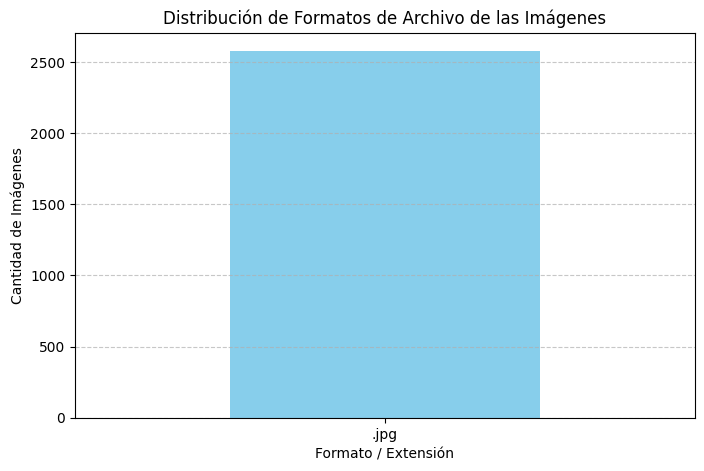

In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Obtener lista de todos los archivos en la carpeta de imágenes
if os.path.exists(images_dir):
    files = os.listdir(images_dir)
    # Extraer la extensión de cada archivo y convertirla a minúsculas
    extensions = [os.path.splitext(f)[1].lower() for f in files if os.path.isfile(os.path.join(images_dir, f))]

    # Crear un contador con Pandas
    df_ext = pd.DataFrame(extensions, columns=['Formato'])
    conteo = df_ext['Formato'].value_counts()

    # Mostrar el conteo en texto
    print("Conteo de formatos de archivos encontrados:")
    print(conteo)

    # Crear gráfico de barras
    plt.figure(figsize=(8, 5))
    conteo.plot(kind='bar', color=['skyblue', 'salmon', 'lightgreen', 'orange'])
    plt.title('Distribución de Formatos de Archivo de las Imágenes')
    plt.xlabel('Formato / Extensión')
    plt.ylabel('Cantidad de Imágenes')
    plt.xticks(rotation=0)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()
else:
    print(f"No se encontró la ruta de imágenes especificada: {images_dir}")

Frecuencia de clases por partición:


,Train,Valid,Test
Counter-Terrorist (ct),1778,522,246
Terrorist (t),1664,476,233


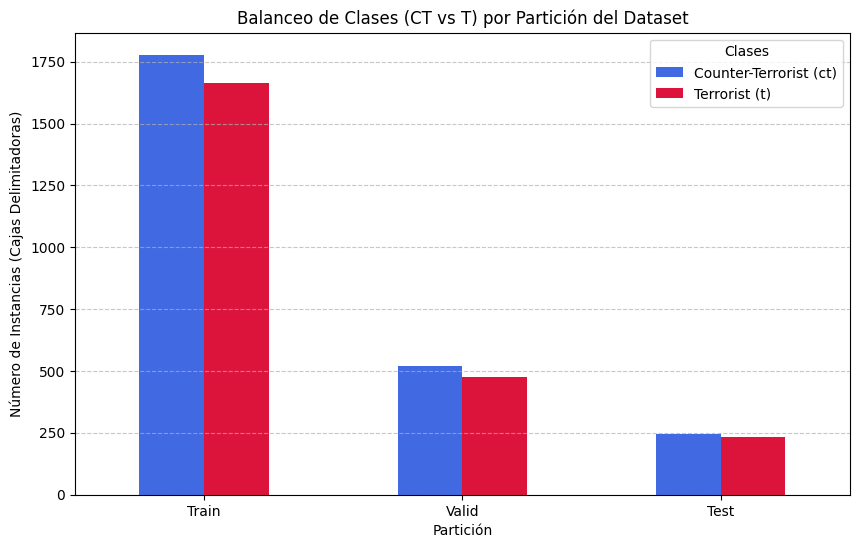

In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt

def contar_clases_en_particion(labels_dir_path):
    counts = {0: 0, 1: 0}
    if not os.path.exists(labels_dir_path):
        return counts

    for label_file in os.listdir(labels_dir_path):
        if label_file.endswith('.txt'):
            with open(os.path.join(labels_dir_path, label_file), 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if parts:
                        try:
                            cls_id = int(parts[0])
                            if cls_id in counts:
                                counts[cls_id] += 1
                        except ValueError:
                            continue
    return counts

# Rutas de las carpetas de etiquetas
particiones = {
    'Train': '/content/Counter-Strike-1/train/labels',
    'Valid': '/content/Counter-Strike-1/valid/labels',
    'Test': '/content/Counter-Strike-1/test/labels'
}

resultados = {}
for nombre, ruta in particiones.items():
    resultados[nombre] = contar_clases_en_particion(ruta)

# Crear un DataFrame para facilitar la graficación
df_balance = pd.DataFrame(resultados).rename(index={0: 'Counter-Terrorist (ct)', 1: 'Terrorist (t)'})

print("Frecuencia de clases por partición:")
display(df_balance)

# Graficar los resultados
fig, ax = plt.subplots(figsize=(10, 6))
df_balance.T.plot(kind='bar', ax=ax, color=['royalblue', 'crimson'])
plt.title('Balanceo de Clases (CT vs T) por Partición del Dataset')
plt.xlabel('Partición')
plt.ylabel('Número de Instancias (Cajas Delimitadoras)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Clases')
plt.show()

Resumen de las dimensiones y canales de las imágenes:


,Ancho,Alto,Canales,Aspect_Ratio
count,2577.0,2577.0,2577.0,2577.0
mean,640.0,640.0,3.0,1.0
std,0.0,0.0,0.0,0.0
min,640.0,640.0,3.0,1.0
25%,640.0,640.0,3.0,1.0
50%,640.0,640.0,3.0,1.0
75%,640.0,640.0,3.0,1.0
max,640.0,640.0,3.0,1.0


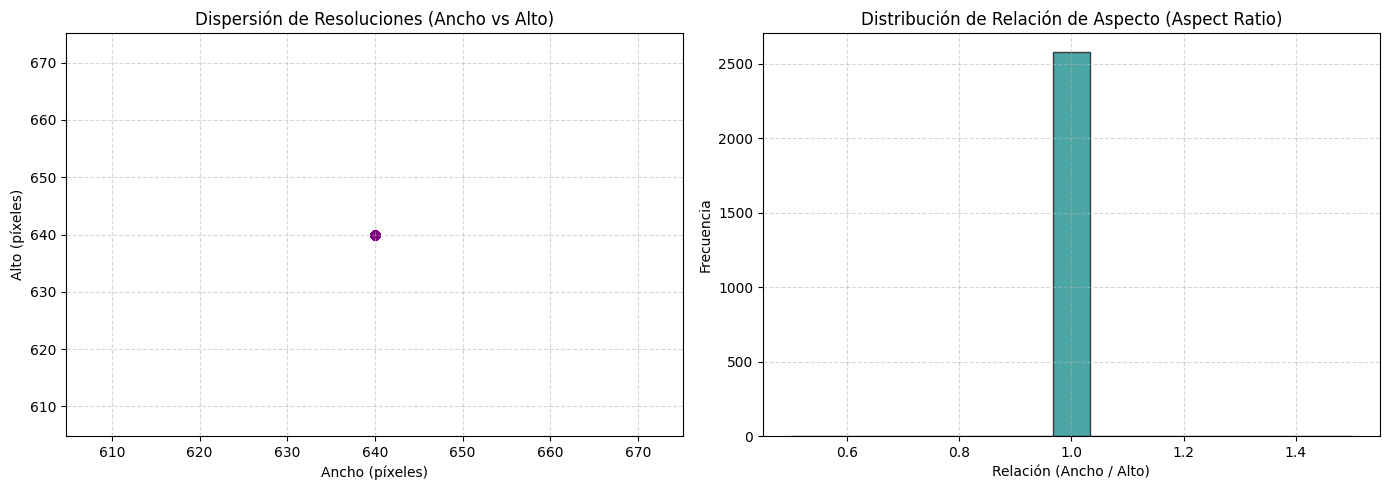

In [10]:
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt

resoluciones = []

if os.path.exists(images_dir):
    all_images = [f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    for img_name in all_images:
        img_path = os.path.join(images_dir, img_name)
        # Leer de forma rápida la imagen
        img = cv2.imread(img_path)
        if img is not None:
            h, w, c = img.shape
            aspect_ratio = w / h
            resoluciones.append({'Ancho': w, 'Alto': h, 'Canales': c, 'Aspect_Ratio': aspect_ratio})

    df_dims = pd.DataFrame(resoluciones)

    # Resumen estadístico
    print("Resumen de las dimensiones y canales de las imágenes:")
    display(df_dims.describe())

    # Crear gráficos de distribución
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Gráfico de dispersión de resoluciones (Ancho vs Alto)
    axes[0].scatter(df_dims['Ancho'], df_dims['Alto'], alpha=0.5, color='purple')
    axes[0].set_title('Dispersión de Resoluciones (Ancho vs Alto)')
    axes[0].set_xlabel('Ancho (píxeles)')
    axes[0].set_ylabel('Alto (píxeles)')
    axes[0].grid(True, linestyle='--', alpha=0.5)

    # Histograma de Relación de Aspecto
    axes[1].hist(df_dims['Aspect_Ratio'], bins=15, color='teal', edgecolor='black', alpha=0.7)
    axes[1].set_title('Distribución de Relación de Aspecto (Aspect Ratio)')
    axes[1].set_xlabel('Relación (Ancho / Alto)')
    axes[1].set_ylabel('Frecuencia')
    axes[1].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()
else:
    print("No se pudo acceder al directorio de imágenes de entrenamiento.")

## Entrenamiento

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=100,
    patience=10,
    imgsz=640,
    batch=16,
    project="runs",
    name="cs_v2",
    exist_ok=True
)

In [ ]:
metrics = model.val(
    imgsz=640,
    project="runs",
    name="cs_v2_VAL",
    exist_ok=True,
    plots=True
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precisión por clase:", metrics.box.maps)


In [11]:
import os
import shutil
import pandas as pd

# 1. Definir rutas locales y de Google Drive
save_dir = "runs/detect/runs/cs_v2"
results_csv_path = os.path.join(save_dir, "results.csv")
local_weights_path = os.path.join(save_dir, "weights", "best.pt")

# Rutas en Google Drive
drive_dest_dir = '/content/drive/MyDrive/CounterStrike_YOLO_Metrics'
csv_output_path = os.path.join(save_dir, "training_metrics_backup.csv")
drive_csv_path = os.path.join(drive_dest_dir, "training_metrics_backup.csv")
drive_weights_dir = os.path.join(drive_dest_dir, "weights")
drive_weights_path = os.path.join(drive_weights_dir, "best.pt")

# Crear directorios locales
os.makedirs(save_dir, exist_ok=True)

# 2. Lógica inteligente de restauración / respaldo de MÉTRICAS y PESOS (.pt)
if os.path.exists(results_csv_path):
    # Escenario A: Acabas de entrenar en esta sesión
    print("¡Se detectó un nuevo entrenamiento en esta sesión!")

    # Guardar y subir métricas
    df_temp = pd.read_csv(results_csv_path)
    df_temp.to_csv(csv_output_path, index=False)
    print(f"Métricas guardadas localmente en: {csv_output_path}")

    try:
        os.makedirs(drive_dest_dir, exist_ok=True)
        shutil.copy(csv_output_path, drive_csv_path)
        print(f"¡Copia de seguridad de métricas actualizada en Google Drive: {drive_csv_path}!")
    except Exception as e:
        print(f"Advertencia: No se pudo respaldar las métricas en Drive: {e}")

    # Respaldar los mejores pesos (best.pt) en Drive
    if os.path.exists(local_weights_path):
        try:
            os.makedirs(drive_weights_dir, exist_ok=True)
            shutil.copy(local_weights_path, drive_weights_path)
            print(f"¡Pesos del modelo (best.pt) respaldados con éxito en Drive: {drive_weights_path}!")
        except Exception as e:
            print(f"Advertencia: No se pudieron copiar los pesos a Google Drive: {e}")
    else:
        print(f"No se encontraron pesos locales en {local_weights_path} para respaldar.")

elif os.path.exists(drive_csv_path):
    # Escenario B: No hay entrenamiento local reciente, pero existe un respaldo en Drive
    print("¡No hay entrenamiento local, pero se encontró un respaldo histórico en Google Drive!")

    # Restaurar métricas CSV
    try:
        shutil.copy(drive_csv_path, csv_output_path)
        print(f"Métricas restauradas con éxito desde Drive a: {csv_output_path}")
    except Exception as e:
        print(f"Error al intentar restaurar el archivo CSV desde Google Drive: {e}")

    # Restaurar pesos YOLO (best.pt) de forma local para predicciones inmediatas
    if os.path.exists(drive_weights_path):
        try:
            local_weights_dir = os.path.dirname(local_weights_path)
            os.makedirs(local_weights_dir, exist_ok=True)
            shutil.copy(drive_weights_path, local_weights_path)
            print(f"Pesos (best.pt) restaurados con éxito de Drive a local: {local_weights_path}")
        except Exception as e:
            print(f"Error al intentar restaurar los pesos desde Google Drive: {e}")
    else:
        print("Nota: No se encontró ningún archivo 'best.pt' guardado en Drive para restaurar.")

else:
    # Escenario C: No hay datos en ningún sitio
    print("No se encontraron métricas locales ni respaldos en Google Drive.")
    print("Por favor, corre el entrenamiento o comprueba que tu Google Drive esté correctamente montado.")

# 3. Cargar el DataFrame definitivo si las comprobaciones fueron exitosas
if os.path.exists(csv_output_path):
    df = pd.read_csv(csv_output_path)
    print("\nEl DataFrame 'df' se ha cargado con éxito y está listo para graficar.")
    display(df.head(10))
else:
    df = None
    print("\nNo se pudo inicializar el DataFrame 'df' porque no hay datos disponibles.")

¡No hay entrenamiento local, pero se encontró un respaldo histórico en Google Drive!
Métricas restauradas con éxito desde Drive a: runs/detect/runs/cs_v2/training_metrics_backup.csv
Nota: No se encontró ningún archivo 'best.pt' guardado en Drive para restaurar.

El DataFrame 'df' se ha cargado con éxito y está listo para graficar.


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,21.9561,1.84545,4.36943,1.22723,0.68248,0.67454,0.73726,0.36531,1.65183,1.57152,1.18995,0.000552,0.000552,0.000552
1,2,40.1456,1.85173,1.46859,1.24166,0.80455,0.60529,0.69502,0.32138,1.84722,1.51658,1.30959,0.001097,0.001097,0.001097
2,3,58.3548,1.82483,1.35851,1.24839,0.83426,0.68479,0.77627,0.37267,1.71108,1.45712,1.26583,0.001631,0.001631,0.001631
3,4,76.3177,1.80339,1.27106,1.23044,0.82906,0.68965,0.78920,0.37686,1.69374,1.25292,1.29470,0.001617,0.001617,0.001617
4,5,94.3946,1.78465,1.20989,1.22352,0.76333,0.68864,0.78598,0.37978,1.66618,1.25354,1.26109,0.001601,0.001601,0.001601
5,6,112.4510,1.75013,1.18424,1.22897,0.83582,0.73710,0.82139,0.40534,1.63347,1.19350,1.24899,0.001584,0.001584,0.001584
6,7,130.4380,1.72363,1.13714,1.20171,0.86753,0.73296,0.82763,0.41087,1.69016,1.02986,1.27141,0.001568,0.001568,0.001568
7,8,148.6090,1.76093,1.12325,1.21524,0.86920,0.78469,0.85641,0.44625,1.57689,1.03306,1.22510,0.001551,0.001551,0.001551
8,9,166.6610,1.69237,1.07506,1.20067,0.89012,0.77739,0.87037,0.43882,1.57028,1.00782,1.23194,0.001535,0.001535,0.001535
9,10,184.6030,1.71572,1.06456,1.20573,0.89151,0.76887,0.85291,0.41592,1.63945,0.98853,1.23970,0.001518,0.001518,0.001518


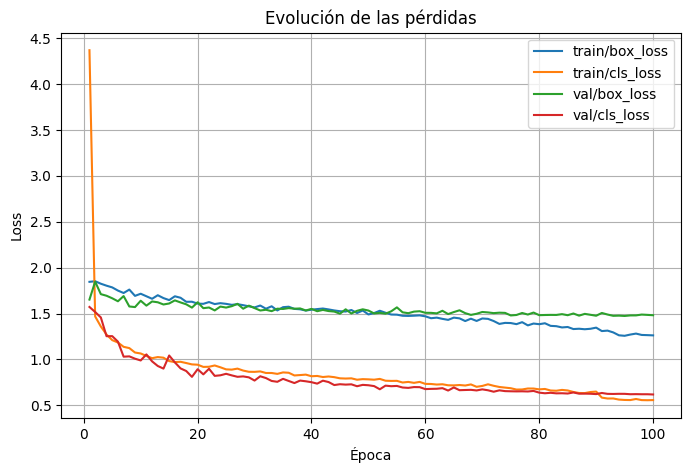

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(df["epoch"], df["train/box_loss"], label="train/box_loss")
plt.plot(df["epoch"], df["train/cls_loss"], label="train/cls_loss")
plt.plot(df["epoch"], df["val/box_loss"], label="val/box_loss")
plt.plot(df["epoch"], df["val/cls_loss"], label="val/cls_loss")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Evolución de las pérdidas")
plt.legend()
plt.grid(True)
plt.show()


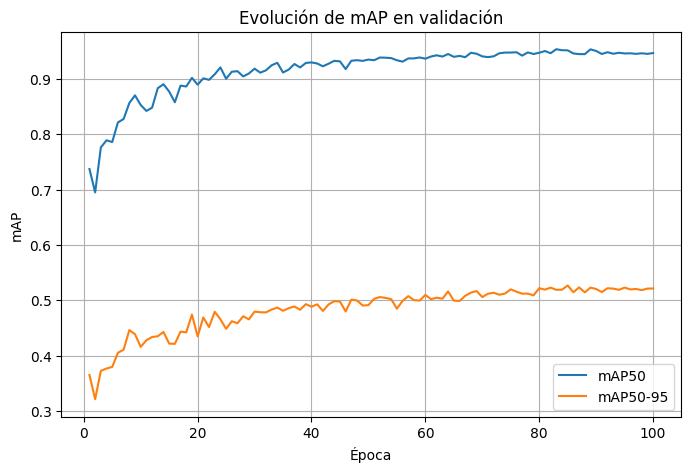

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50")
plt.plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP50-95")
plt.xlabel("Época")
plt.ylabel("mAP")
plt.title("Evolución de mAP en validación")
plt.legend()
plt.grid(True)
plt.show()


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Imagen seleccionada aleatoriamente: /content/Counter-Strike-1/train/images/csdata_628_png.rf.bcfa2fd08addcc3ea0e829d2d9ff42ae.jpg
El modelo no estaba en memoria. Buscando pesos guardados para cargarlo...
No se encontraron pesos de entrenamientos anteriores (best.pt).
Cargando el modelo base preentrenado (yolo11n.pt) por defecto para demostración.

image 1/1 /content/Counter-Strike-1/train/images/csdata_628_png.rf.bcfa2fd08addcc3ea0e829d2d9ff42ae.jpg: 640x640 1 person, 11.1ms
Speed: 93.9ms preprocess, 11.1ms inference, 23.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/runs/cs_v2_pred


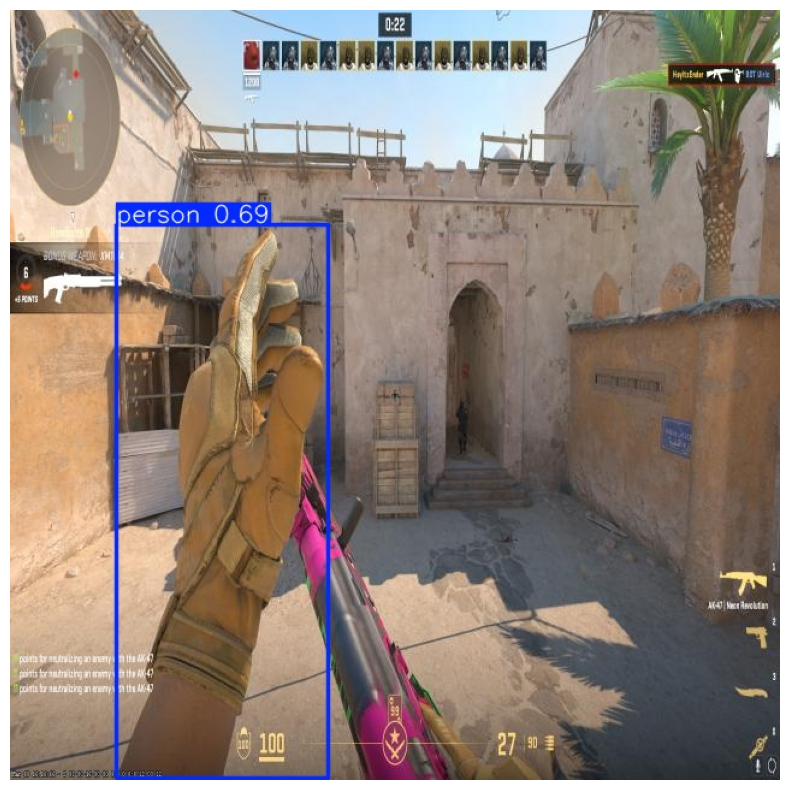

In [14]:
import matplotlib.pyplot as plt
import cv2
import os
import random
from ultralytics import YOLO

# 1. Definir el directorio de imágenes de entrenamiento
train_images_dir = "/content/Counter-Strike-1/train/images"

# Seleccionar una imagen al azar
if os.path.exists(train_images_dir):
    all_train_images = [f for f in os.listdir(train_images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    if all_train_images:
        random_img_name = random.choice(all_train_images)
        img_path = os.path.join(train_images_dir, random_img_name)
        print(f"Imagen seleccionada aleatoriamente: {img_path}")
    else:
        raise FileNotFoundError("No se encontraron imágenes en el directorio de entrenamiento.")
else:
    raise FileNotFoundError(f"No existe el directorio: {train_images_dir}")

# 2. Asegurar que el modelo esté cargado en memoria
if 'model' in globals() and model is not None:
    print("Utilizando el modelo activo encontrado en la memoria del kernel.")
else:
    print("El modelo no estaba en memoria. Buscando pesos guardados para cargarlo...")
    local_weights_path = "runs/detect/runs/cs_v2/weights/best.pt"
    drive_weights_path = "/content/drive/MyDrive/CounterStrike_YOLO_Metrics/weights/best.pt" # Ruta por si quieres respaldar tus pesos en Drive

    # Si no tienes los pesos respaldados en Drive de un entrenamiento previo, definimos las opciones:
    if os.path.exists(local_weights_path):
        print(f"Cargando pesos desde el entrenamiento local en: {local_weights_path}")
        model = YOLO(local_weights_path)
    elif os.path.exists(drive_weights_path):
        print(f"Cargando pesos desde el respaldo en Google Drive en: {drive_weights_path}")
        model = YOLO(drive_weights_path)
    else:
        print("No se encontraron pesos de entrenamientos anteriores (best.pt).")
        print("Cargando el modelo base preentrenado (yolo11n.pt) por defecto para demostración.")
        model = YOLO("yolo11n.pt")

# 3. Realizar predicción
preds = model.predict(
    source=img_path,
    imgsz=640,
    conf=0.4,
    save=True,
    project="runs",
    name="cs_v2_pred",
    exist_ok=True
)

# 4. Cargar y mostrar la imagen resultante
result_image_path = os.path.join(preds[0].save_dir, os.path.basename(preds[0].path))

if os.path.exists(result_image_path):
    img = cv2.imread(result_image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.show()
else:
    print(f"No se pudo encontrar la imagen de predicción en la ruta: {result_image_path}")